# Modeling: training, selection and calibration

Training uses 2013-2020, model selection and early stopping use `val_select` (2021), and
isotonic calibration uses `val_calib` (2022). Held-out geographic labels never enter any of
these stages. This notebook reads closed selection records and saved model objects; it runs
no training, selection, calibration fitting or inference. All displayed performance values
are recorded validation results.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from bolivia_fire.config import REPO_ROOT
from bolivia_fire.figures import COLORS, chart_style
from bolivia_fire.firms.storage import sha256_file

root = REPO_ROOT
selection = json.loads(
    (root / "artifacts/evaluation/selection_strict.json").read_text(encoding="utf-8")
)
geo = json.loads(
    (root / "artifacts/evaluation/selection_strict_geo.json").read_text(encoding="utf-8")
)
run = json.loads((root / "artifacts/models/strict/run.json").read_text(encoding="utf-8"))
assert run["run_token"] == selection["run_token"]
selected = selection["selected_model"]
print("Selection rule:", selection["selection_rule"])
print("Selected strict candidate:", selected)
print("Selected baseline:", selection["best_baseline"])
display(pd.DataFrame(selection["exclusions"]).T)

Selection rule: uncalibrated val_select average_precision
Selected strict candidate: lightgbm_08
Selected baseline: train_climatology


,scanned,purged_partition,missing_label,geographic_holdout,incomplete_28d,target_low_coverage,eligible
train,15564174,111438,74292,3162960,236048,0,11979436
val_select,2005884,111438,37146,382000,118024,0,1357276
val_calib,2005884,111438,148584,359080,206542,0,1180240


## Baselines and logistic regression

The **cell climatology** baseline uses the smoothed training-label probability defined in the
feature notebook, clipped to [0.000001, 0.999999]. Its training probabilities are LOYO.
The geographic variant substitutes department climatology. **Persistence** learns four
training probabilities for preceding seven-day detection counts 0, 1, 2-4 and at least 5;
it is not a hard copy of the previous label.

**Logistic regression** uses log1p for nonnegative continuous inputs, then training means and
scales; missing values are filled with those training means. Calendar, boolean and observation
flags bypass log1p. All positives and a seeded 10% sample of negatives are used for the logistic
fit; inverse sampling weights restore negative mass. The transform uses the full training
population. Validation keeps all eligible rows.

The following scores are uncalibrated 2021 values. The baseline with highest validation AP is
fixed before final evaluation. Isotonic mapping can create ties and change AP, so probability
versions remain explicit throughout.

In [2]:
final_names = ["train_climatology", "persistence", "logistic_regression", selected]
validation_rows = []
for name in final_names:
    metrics = selection["candidates"][name]["val_select"]["uncalibrated"]
    validation_rows.append(
        {
            "Model": name,
            "AP": metrics["average_precision"],
            "Brier": metrics["brier_score"],
            "Log loss": metrics["log_loss"],
            "ROC AUC": metrics["roc_auc"],
            "Rows": metrics["rows"],
        }
    )
display(pd.DataFrame(validation_rows).set_index("Model"))
display(
    pd.Series(
        run["candidates"]["logistic_regression"]["parameters"], name="Recorded logistic fit"
    ).to_frame()
)
persistence_path = root / "artifacts/models/strict/persistence.joblib"
assert sha256_file(persistence_path) == selection["model_ids"]["persistence"]
persistence = joblib.load(persistence_path)
display(
    pd.DataFrame(
        {
            "Previous 7-day count": ["0", "1", "2-4", ">=5"],
            "Training probability": persistence.estimator.probabilities,
        }
    )
)

,AP,Brier,Log loss,ROC AUC,Rows
Model,,,,,
train_climatology,0.218512,0.019184,0.106154,0.858046,1357276
persistence,0.148052,0.019586,0.091990,0.650873,1357276
logistic_regression,0.326496,0.017694,0.069925,0.924399,1357276
lightgbm_08,0.346855,0.017539,0.069103,0.929182,1357276


,Recorded logistic fit
negative_fraction,0.1
negative_weight,9.999997
sampled_rows,1427749
solver,lbfgs


,Previous 7-day count,Training probability
0,0,0.016145
1,1,0.181885
2,2-4,0.253592
3,>=5,0.415100


## Frozen 20-configuration LightGBM search

The random search uses seed 7 and the frozen space in `configs/experiments.yaml`. Each configuration
has at most 400 boosting rounds, early stopping after 30 rounds without improvement, max_bin 63
and four threads. All eligible training rows are retained. Configuration parameters and stopping
rounds below come from the matching saved run; APs come from `selection_strict.json`.
The highlighted configuration has the largest uncalibrated 2021 AP.

,num_leaves,learning_rate,min_data_in_leaf,feature_fraction,lambda_l2,best_iteration,Validation AP,Selected
Configuration,,,,,,,,
lightgbm_00,63,0.06,1000,1.00,1,12,0.336938,False
lightgbm_01,63,0.10,50,0.70,0,12,0.330036,False
lightgbm_02,15,0.10,1000,0.70,1,83,0.332053,False
lightgbm_03,63,0.03,1000,0.70,1,28,0.344464,False
lightgbm_04,63,0.03,200,0.70,10,44,0.343805,False
lightgbm_05,15,0.10,200,0.85,1,29,0.335276,False
lightgbm_06,31,0.06,200,1.00,10,14,0.340608,False
lightgbm_07,63,0.10,200,0.85,10,29,0.316499,False
lightgbm_08,15,0.03,1000,0.70,10,78,0.346855,True


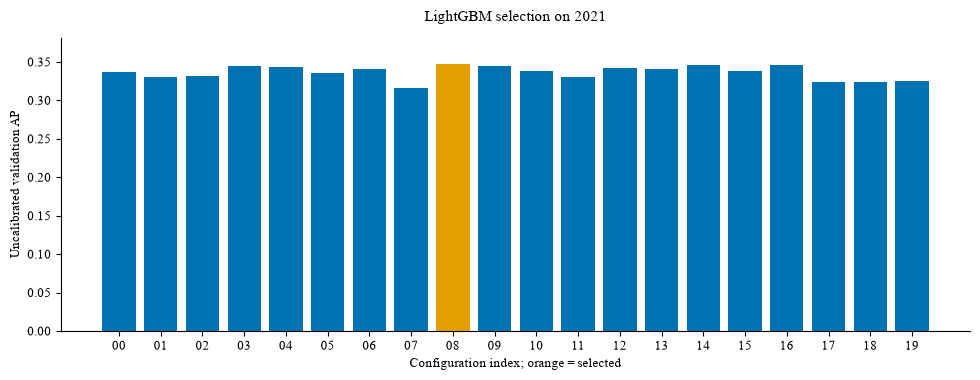

Chart font: Times New Roman


In [3]:
parameter_names = [
    "num_leaves",
    "learning_rate",
    "min_data_in_leaf",
    "feature_fraction",
    "lambda_l2",
    "best_iteration",
]
search_rows = []
for name, result in selection["candidates"].items():
    if name.startswith("lightgbm_"):
        search_rows.append(
            {
                "Configuration": name,
                **{key: run["candidates"][name]["parameters"][key] for key in parameter_names},
                "Validation AP": result["val_select"]["uncalibrated"]["average_precision"],
                "Selected": name == selected,
            }
        )
search = pd.DataFrame(search_rows).sort_values("Configuration").reset_index(drop=True)
assert len(search) == selection["config"]["lightgbm_search"]["configurations"] == 20
assert (
    search.loc[search["Validation AP"].idxmax(), "Configuration"] == selection["selected_lightgbm"]
)
display(search.set_index("Configuration"))
with chart_style() as font:
    figure, ax = plt.subplots(figsize=(10, 4), layout="constrained")
    ax.bar(
        np.arange(len(search)),
        search["Validation AP"],
        color=[COLORS[1] if value else COLORS[0] for value in search.Selected],
    )
    ax.set_xticks(np.arange(len(search)), search.Configuration.str.removeprefix("lightgbm_"))
    ax.set_xlabel("Configuration index; orange = selected")
    ax.set_ylabel("Uncalibrated validation AP")
    ax.set_title("LightGBM selection on 2021")
    ax.set_ylim(0, search["Validation AP"].max() * 1.1)
    plt.show()
print("Chart font:", font)

## Isotonic calibration on 2022

The saved isotonic mapping is fitted on `val_calib` only. The 2022 reliability plot is therefore
an apparent calibration check on the fitting population, not an independent assessment of
calibration quality. The adjacent 2021 plot shows the same mapping on the earlier selection
population. Neither panel supplies an unbiased generalization estimate.

Each point is one recorded equal-frequency bin, before or after calibration. Bin masses may be
fractional because boundary observations are split to equalize mass. The identity line denotes
perfect reliability. No probabilities, bins or metrics are recomputed here.

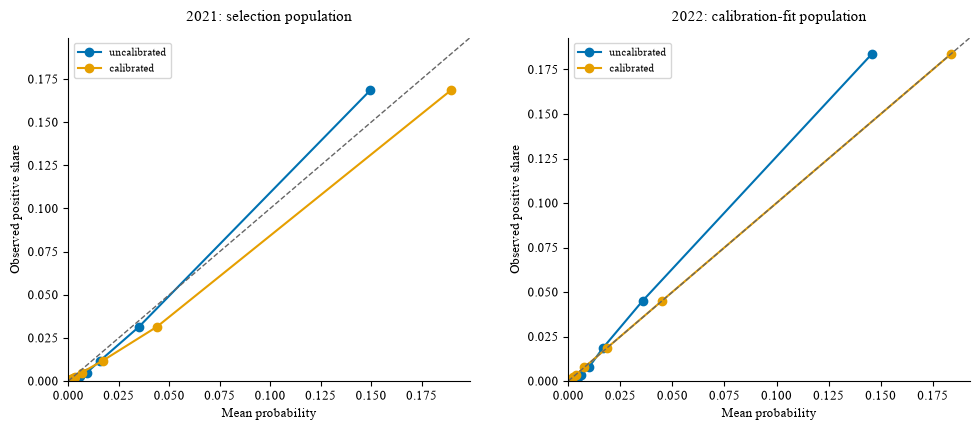

Brier  Log loss       ECE        AP     Rows
Partition  Probability                                                  
val_select uncalibrated  0.017539  0.069103  0.004706  0.346855  1357276
           calibrated    0.017442  0.068346  0.004215  0.341695  1357276
val_calib  uncalibrated  0.021261  0.082471  0.006673  0.319169  1180240
           calibrated    0.020989  0.080765  0.000071  0.316166  1180240

In [4]:
calibration_rows = []
with chart_style():
    figure, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
    for ax, split, title in zip(
        axes,
        ["val_select", "val_calib"],
        ["2021: selection population", "2022: calibration-fit population"],
        strict=True,
    ):
        for version, color in [("uncalibrated", COLORS[0]), ("calibrated", COLORS[1])]:
            metrics = selection["candidates"][selected][split][version]
            bins = pd.DataFrame(metrics["reliability"])
            ax.plot(bins.mean_probability, bins.positive_rate, "o-", color=color, label=version)
            calibration_rows.append(
                {
                    "Partition": split,
                    "Probability": version,
                    "Brier": metrics["brier_score"],
                    "Log loss": metrics["log_loss"],
                    "ECE": metrics["expected_calibration_error"],
                    "AP": metrics["average_precision"],
                    "Rows": metrics["rows"],
                }
            )
        upper = max(ax.get_xlim()[1], ax.get_ylim()[1])
        ax.plot([0, upper], [0, upper], "--", color="0.4", linewidth=1)
        ax.set(
            xlim=(0, upper),
            ylim=(0, upper),
            xlabel="Mean probability",
            ylabel="Observed positive share",
            title=title,
        )
        ax.legend()
    plt.show()
display(pd.DataFrame(calibration_rows).set_index(["Partition", "Probability"]))

## Selected model gain importance

The saved strict model is loaded read-only after checking its recorded SHA256 identifier.
Gain is the total training split improvement attributed to a feature; correlated predictors
can share or substitute for that gain. It is not a causal effect or a validation performance
contribution. This inspection uses the existing tree structure and needs no new predictions.

,Gain,Gain share
Feature,,
neighborhood_3x3_last_28d,4.359717e+06,0.318037
train_climatology_cell,4.259387e+06,0.310718
neighborhood_7x7_last_28d,1.817198e+06,0.132563
days_since_last,8.930294e+05,0.065146
neighborhood_3x3_last_7d,4.765288e+05,0.034762
neighborhood_7x7_last_7d,3.527504e+05,0.025733
count_last_28d,3.031844e+05,0.022117
count_last_14d,2.833892e+05,0.020673
no_prior_detection,2.078763e+05,0.015164


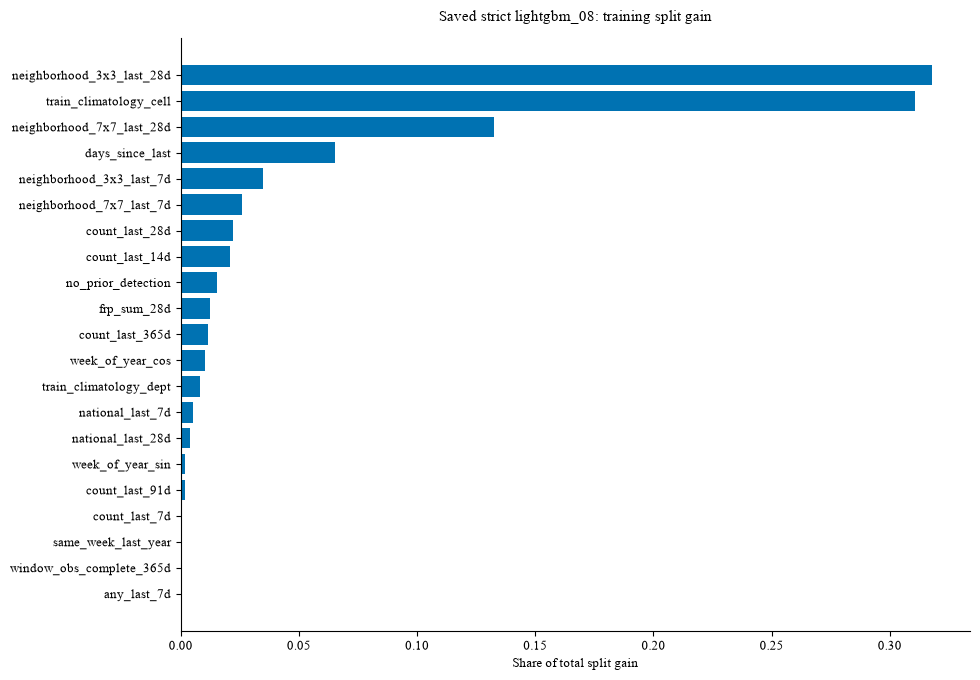

In [5]:
model_path = root / f"artifacts/models/strict/{selected}.joblib"
assert sha256_file(model_path) == selection["model_ids"][selected]
model = joblib.load(model_path)
assert model.features == selection["features"]
gain = model.estimator.feature_importance(importance_type="gain")
importance = pd.DataFrame({"Feature": model.features, "Gain": gain})
importance["Gain share"] = importance.Gain / importance.Gain.sum()
importance = importance.sort_values("Gain", ascending=False).reset_index(drop=True)
display(importance.set_index("Feature"))
with chart_style():
    figure, ax = plt.subplots(figsize=(10, 7), layout="constrained")
    ordered = importance.sort_values("Gain")
    ax.barh(ordered.Feature, ordered["Gain share"], color=COLORS[0])
    ax.set_xlabel("Share of total split gain")
    ax.set_title(f"Saved strict {selected}: training split gain")
    plt.show()

## Strict and strict_geo feature sets

`strict_geo` omits cell climatology because held-out cells have no eligible cell-label training
history. Department climatology remains and uses non-held-out training cell-weeks. Past
held-out detections may contribute to recency, neighborhoods and national history; held-out
labels never enter training, model selection, calibration or climatology. Both variants use
the same training and validation years and independently select their candidates.

In [6]:
strict_names, geo_names = selection["features"], geo["features"]
assert set(strict_names) - set(geo_names) == {"train_climatology_cell"}
assert not set(geo_names) - set(strict_names)
display(
    pd.DataFrame(
        {
            "Feature": strict_names,
            "strict": True,
            "strict_geo": [name in geo_names for name in strict_names],
        }
    ).set_index("Feature")
)
display(
    pd.DataFrame(
        [
            {
                "Variant": name,
                "Selected model": item["selected_model"],
                "Best baseline": item["best_baseline"],
                "Feature count": len(item["features"]),
                "Uncalibrated validation AP": item["candidates"][item["selected_model"]][
                    "val_select"
                ]["uncalibrated"]["average_precision"],
            }
            for name, item in [("strict", selection), ("strict_geo", geo)]
        ]
    ).set_index("Variant")
)
display(Markdown("Continue with the [recorded evaluation](04_evaluation.ipynb)."))

,strict,strict_geo
Feature,,
count_last_7d,True,True
count_last_14d,True,True
count_last_28d,True,True
count_last_91d,True,True
count_last_365d,True,True
any_last_7d,True,True
days_since_last,True,True
no_prior_detection,True,True
frp_sum_28d,True,True


,Selected model,Best baseline,Feature count,Uncalibrated validation AP
Variant,,,,
strict,lightgbm_08,train_climatology,21,0.346855
strict_geo,lightgbm_04,persistence,20,0.326202


Continue with the [recorded evaluation](04_evaluation.ipynb).